# Phase 6b — Quantifying Embedding Structure

Revision step 11 from `NEXT_STEPS.md` (PeerJ resubmission). The draft makes three claims from the UMAP plot (Figure 10):

1. the joint space shows "clear quadrant-level clustering";
2. Q4 (Calm) forms the tightest cluster and Q2 (Angry) has the widest overlap;
3. low-coherence tracks "concentrate disproportionately at quadrant boundaries".

UMAP distorts distances, so these are replaced with measurements in the original embedding spaces:
* **silhouette scores** (cosine) by quadrant, against a label-permutation null, overall and per quadrant;
* **linear-probe classification** of quadrant (logistic regression, shared train → shared val for C → shared test);
* **rank tests** relating per-track silhouette to the cross-fitted coherence from Phase 4b.

Quadrant labels are the evaluation target here; `moods`, `genres` and `themes` are not used.

**Update (MuQ as primary audio encoder).** Phase 5e showed MuQ (`MuQ-large-msd-iter`) is the strongest audio
representation, so two spaces are added: `audio: MuQ` (layer 6, z-scored per dimension without labels, L2-normalised;
the 5e validation choice for both retrieval and the quadrant probe) and `early fusion (MuQ+SBERT)`. The boundary
analysis (section 3) is repeated with the MuQ-based coherence from Phase 4c. The new spaces are evaluated after the
original ones, so the random draws, and therefore the numbers, for the original spaces are unchanged.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, mannwhitneyu
from sklearn.metrics import pairwise_distances, silhouette_score, silhouette_samples, accuracy_score, f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from umap import UMAP

warnings.filterwarnings('ignore')

ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUT_DIR = os.path.join(ROOT, 'outputs')
SEED    = 42
N_PERM  = 200
N_BOOT  = 2000
QUADS   = ['Q1', 'Q2', 'Q3', 'Q4']
QLAB    = {'Q1': 'Happy', 'Q2': 'Angry', 'Q3': 'Sad', 'Q4': 'Calm'}
QCOL    = {'Q1': '#f4a261', 'Q2': '#e63946', 'Q3': '#457b9d', 'Q4': '#2a9d8f'}
rng = np.random.default_rng(SEED)

audio_df  = pd.read_parquet(os.path.join(OUT_DIR, 'audio_features.parquet'))
lyrics_df = pd.read_parquet(os.path.join(OUT_DIR, 'lyrics_features.parquet'))
merged    = pd.read_parquet(os.path.join(OUT_DIR, 'merged_dataset.parquet'))
coh       = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_v2.parquet')).set_index('song_id')

def l2n(X):
    X = np.asarray(X, dtype=np.float64)
    return X / np.linalg.norm(X, axis=1, keepdims=True)

sids = lyrics_df['song_id'].tolist()
arow = {s: i for i, s in enumerate(audio_df['song_id'])}
ai   = [arow[s] for s in sids]
quad = merged.set_index('song_id').loc[sids, 'quadrant'].values

SPACES = {
    'audio: CLAP':          l2n(np.vstack(audio_df['audio_clap'].values)[ai]),
    'audio: handcrafted':   np.vstack(audio_df['audio_handcrafted'].values)[ai].astype(np.float64),
    'lyrics: SBERT':        l2n(np.vstack(lyrics_df['lyrics_sbert'].values)),
    'lyrics: NRC':          np.vstack(lyrics_df['lyrics_nrc'].values).astype(np.float64),
    'early fusion (CLAP+SBERT)': l2n(np.hstack([np.vstack(audio_df['audio_clap_raw'].values)[ai],
                                                np.vstack(lyrics_df['lyrics_sbert_raw'].values)])),
}
ENC_DIR = os.path.join(OUT_DIR, 'encoders')
a_ids = pd.read_csv(os.path.join(ENC_DIR, 'audio_song_ids.csv'))['song_id'].tolist()
mrow  = {s: i for i, s in enumerate(a_ids)}
muq6  = np.load(os.path.join(ENC_DIR, 'audio_muq.npy'), mmap_mode='r')[[mrow[s] for s in sids], 6].astype(np.float64)
muq6  = l2n(StandardScaler().fit_transform(muq6))                    # unsupervised z-score, as in Phase 5e
coh_muq = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_muq.parquet')).set_index('song_id')
SPACES_NEW = {
    'audio: MuQ':               muq6,
    'early fusion (MuQ+SBERT)': l2n(np.hstack([muq6, l2n(np.vstack(lyrics_df['lyrics_sbert'].values))])),
}
ORIG = list(SPACES)
SPACES.update(SPACES_NEW)                                            # evaluated after the original spaces
for k, v in SPACES.items():
    print(f'{k:28s} {v.shape}')

audio: CLAP                  (2075, 512)
audio: handcrafted           (2075, 141)
lyrics: SBERT                (2075, 768)
lyrics: NRC                  (2075, 10)
early fusion (CLAP+SBERT)    (2075, 1280)
audio: MuQ                   (2075, 1024)
early fusion (MuQ+SBERT)     (2075, 1792)


## 1. Silhouette scores by quadrant
Cosine silhouette for the embedding spaces (CLAP, SBERT, early fusion); the handcrafted and NRC features are
standardised first and use Euclidean distance. The null distribution comes from 200 random permutations of the
quadrant labels. The 2-D UMAP of Figure 10 (same settings as Phase 6) is included to show how much UMAP inflates structure.

In [2]:
def space_for_silhouette(name):
    X = SPACES[name]
    if name in ('audio: handcrafted', 'lyrics: NRC'):
        return StandardScaler().fit_transform(X), 'euclidean'
    return X, 'cosine'

umap_xy = UMAP(n_neighbors=30, min_dist=0.1, n_components=2, metric='cosine',
               random_state=SEED, verbose=False).fit_transform(SPACES['early fusion (CLAP+SBERT)'])

rows, per_track = [], {}
for name in ORIG + ['UMAP 2-D of early fusion (Figure 10)'] + list(SPACES_NEW):
    if name.startswith('UMAP'):
        X, metric = umap_xy, 'euclidean'
    else:
        X, metric = space_for_silhouette(name)
    D = pairwise_distances(X, metric=metric)                       # computed once, reused for the null
    s_i = silhouette_samples(D, quad, metric='precomputed')
    per_track[name] = s_i
    null = np.array([silhouette_score(D, rng.permutation(quad), metric='precomputed') for _ in range(N_PERM)])
    row = {'space': name, 'silhouette': s_i.mean(), 'null_mean': null.mean(), 'null_95th': np.percentile(null, 95),
           'perm_p': (np.sum(null >= s_i.mean()) + 1) / (N_PERM + 1), 'share_tracks_positive': np.mean(s_i > 0)}
    for q in QUADS:
        row[f'sil_{q}'] = s_i[quad == q].mean()
    rows.append(row)
sil = pd.DataFrame(rows)
print('Silhouette range is [−1, 1]; values near 0 mean overlapping clusters.')
print(sil.round(4).to_string(index=False))
sil.to_csv(os.path.join(OUT_DIR, 'embedding_silhouette.csv'), index=False)

Silhouette range is [−1, 1]; values near 0 mean overlapping clusters.
                               space  silhouette  null_mean  null_95th  perm_p  share_tracks_positive  sil_Q1  sil_Q2  sil_Q3  sil_Q4
                         audio: CLAP     -0.1302    -0.0451    -0.0193   1.000                 0.3441 -0.1972 -0.2985 -0.0955  0.0998
                  audio: handcrafted      0.0274    -0.0088    -0.0055   0.005                 0.5258  0.0368  0.1374 -0.0582 -0.0277
                       lyrics: SBERT      0.0257    -0.0061    -0.0043   0.005                 0.6651  0.0351  0.0418  0.0454 -0.0213
                         lyrics: NRC      0.0030    -0.0122    -0.0077   0.005                 0.4511 -0.0759  0.1739 -0.1160 -0.0020
           early fusion (CLAP+SBERT)      0.0252    -0.0063    -0.0046   0.005                 0.6631  0.0334  0.0392  0.0475 -0.0208
UMAP 2-D of early fusion (Figure 10)      0.0875    -0.0167    -0.0110   0.005                 0.6313 -0.0096  0.3322  0.1061 

### Per-quadrant silhouette with bootstrap CIs (early fusion spaces, CLAP- and MuQ-based)
Tests the "Q4 tightest, Q2 widest overlap" claim. CIs resample tracks within each quadrant.

In [3]:
qrows = []
for space in ['early fusion (CLAP+SBERT)', 'early fusion (MuQ+SBERT)']:
  s_ef = per_track[space]
  for q in QUADS:
    x = s_ef[quad == q]
    bs = x[rng.integers(0, len(x), (N_BOOT, len(x)))].mean(1)
    qrows.append({'space': space, 'quadrant': f'{q} {QLAB[q]}', 'n': len(x), 'mean_silhouette': x.mean(),
                  'ci_lo': np.percentile(bs, 2.5), 'ci_hi': np.percentile(bs, 97.5), 'share_positive': np.mean(x > 0)})
qsil = pd.DataFrame(qrows)
print(qsil.round(4).to_string(index=False))

                    space quadrant   n  mean_silhouette   ci_lo   ci_hi  share_positive
early fusion (CLAP+SBERT) Q1 Happy 509           0.0334  0.0279  0.0388          0.6994
early fusion (CLAP+SBERT) Q2 Angry 583           0.0392  0.0328  0.0454          0.7204
early fusion (CLAP+SBERT)   Q3 Sad 480           0.0475  0.0433  0.0521          0.8354
early fusion (CLAP+SBERT)  Q4 Calm 503          -0.0208 -0.0267 -0.0149          0.3956
 early fusion (MuQ+SBERT) Q1 Happy 509           0.0544  0.0508  0.0582          0.8978
 early fusion (MuQ+SBERT) Q2 Angry 583           0.0929  0.0879  0.0982          0.9297
 early fusion (MuQ+SBERT)   Q3 Sad 480           0.0310  0.0282  0.0338          0.8604
 early fusion (MuQ+SBERT)  Q4 Calm 503          -0.0066 -0.0094 -0.0036          0.4394


## 2. Linear-probe quadrant classification
Logistic regression on standardised features. Trained on the shared 70/15/15 train split (tracks in the train subset
of both MERGE splits; see Phase 5b), C chosen on the shared validation split by macro-F1, scored once on the shared
test split (n = 302). CIs are percentile bootstraps over test tracks. Chance = 0.25.

In [4]:
cat = set(sids)
mm  = merged[merged['is_multimodal']]
lyr_stem_to_sid = {os.path.splitext(os.path.basename(p))[0]: s for s, p in zip(mm['song_id'], mm['lyrics_path'])}
def read_split(modality, subset, scheme='tvt_70_15_15'):
    folder = 'MERGE_Audio_Balanced' if modality == 'audio' else 'MERGE_Lyrics_Balanced'
    ids = pd.read_csv(os.path.join(ROOT, folder, 'tvt_dataframes', scheme,
                                   f'{scheme}_{subset}_{modality}_balanced.csv'))['Song']
    return set(ids.map(lyr_stem_to_sid).dropna()) if modality == 'lyrics' else set(ids)
mask = {sub: np.isin(sids, list(read_split('audio', sub) & read_split('lyrics', sub) & cat))
        for sub in ['train', 'validate', 'test']}
tr, va, te = mask['train'], mask['validate'], mask['test']
print({k: int(v.sum()) for k, v in mask.items()})

C_GRID = np.logspace(-4, 2, 13)
probe_rows, test_preds = [], {}
for name, X in SPACES.items():
    best = None
    for C in C_GRID:
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))
        clf.fit(X[tr], quad[tr])
        f1 = f1_score(quad[va], clf.predict(X[va]), average='macro')
        if best is None or f1 > best[0]:
            best = (f1, C, clf)
    _, C, clf = best
    pred = clf.predict(X[te]); test_preds[name] = pred
    correct = (pred == quad[te]).astype(float)
    idx = rng.integers(0, te.sum(), (N_BOOT, te.sum()))
    acc_bs = correct[idx].mean(1)
    f1_bs = np.array([f1_score(quad[te][i], pred[i], average='macro') for i in idx[:500]])
    row = {'features': name, 'C': C, 'val_macro_f1': best[0],
           'test_acc': correct.mean(), 'acc_ci_lo': np.percentile(acc_bs, 2.5), 'acc_ci_hi': np.percentile(acc_bs, 97.5),
           'test_macro_f1': f1_score(quad[te], pred, average='macro'),
           'f1_ci_lo': np.percentile(f1_bs, 2.5), 'f1_ci_hi': np.percentile(f1_bs, 97.5)}
    for q in QUADS:
        row[f'recall_{q}'] = np.mean(pred[quad[te] == q] == q)
    probe_rows.append(row)
probe = pd.DataFrame(probe_rows)
print(probe.round(3).to_string(index=False))
probe.to_csv(os.path.join(OUT_DIR, 'linear_probe_quadrant.csv'), index=False)

# Paired bootstrap on accuracy differences
def paired_diff(a, b):
    ca = (test_preds[a] == quad[te]).astype(float); cb = (test_preds[b] == quad[te]).astype(float)
    d = ca - cb; idx = rng.integers(0, len(d), (N_BOOT, len(d)))
    bs = d[idx].mean(1)
    return d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)
print('\nPaired accuracy differences (bootstrap 95% CI):')
for a, b in [('lyrics: SBERT', 'audio: CLAP'), ('early fusion (CLAP+SBERT)', 'lyrics: SBERT'),
             ('audio: CLAP', 'audio: handcrafted'), ('lyrics: SBERT', 'lyrics: NRC'),
             ('audio: MuQ', 'audio: CLAP'), ('audio: MuQ', 'lyrics: SBERT'),
             ('early fusion (MuQ+SBERT)', 'lyrics: SBERT'), ('early fusion (MuQ+SBERT)', 'early fusion (CLAP+SBERT)')]:
    m, lo, hi = paired_diff(a, b)
    print(f'  {a} − {b}: {m:+.3f} [{lo:+.3f}, {hi:+.3f}]')

for ef in ['early fusion (CLAP+SBERT)', 'early fusion (MuQ+SBERT)']:
    print(f'\nConfusion matrix, {ef} (rows = true, cols = predicted):')
    print(pd.DataFrame(confusion_matrix(quad[te], test_preds[ef], labels=QUADS), index=QUADS, columns=QUADS).to_string())

{'train': 1187, 'validate': 305, 'test': 302}


                 features     C  val_macro_f1  test_acc  acc_ci_lo  acc_ci_hi  test_macro_f1  f1_ci_lo  f1_ci_hi  recall_Q1  recall_Q2  recall_Q3  recall_Q4
              audio: CLAP 0.032         0.541     0.434      0.377      0.490          0.441     0.385     0.492      0.387      0.600      0.377      0.373
       audio: handcrafted 0.100         0.651     0.603      0.546      0.656          0.603     0.546     0.656      0.680      0.787      0.506      0.440
            lyrics: SBERT 0.001         0.700     0.722      0.672      0.772          0.718     0.666     0.762      0.573      0.920      0.662      0.733
              lyrics: NRC 0.100         0.387     0.493      0.437      0.553          0.471     0.412     0.527      0.400      0.867      0.260      0.453
early fusion (CLAP+SBERT) 0.003         0.732     0.758      0.712      0.808          0.759     0.708     0.807      0.627      0.880      0.779      0.747
               audio: MuQ 0.003         0.774     0.762   

## 3. Are low-coherence tracks at the quadrant boundaries?
A track with a low (or negative) silhouette sits closer to another quadrant's tracks than to its own, i.e. at a boundary
in the embedding space. If the draft's claim holds, coherence should correlate positively with silhouette, and robust
paradoxes (Phase 4b) should have lower silhouettes than robust-coherent tracks. Repeated with the MuQ-based coherence from Phase 4c. We also check boundary position in the
label space: distance of the annotated AV point from the nearest quadrant boundary.

In [5]:
c0 = coh.loc[sids]
av_boundary_dist = np.minimum(np.abs(c0['arousal'] - 0.5), np.abs(c0['valence'] - 0.5)).values
brows = []
for coh_name, coh_src, names in [
        ('CLAP (4b)', coh, ['early fusion (CLAP+SBERT)', 'audio: CLAP', 'lyrics: SBERT', 'UMAP 2-D of early fusion (Figure 10)']),
        ('MuQ (4c)', coh_muq, ['early fusion (MuQ+SBERT)', 'audio: MuQ', 'lyrics: SBERT'])]:
  c = coh_src.loc[sids]
  for name in names:
    s_i = per_track[name]
    r, p = spearmanr(c['coh_cos'], s_i)
    rp = s_i[(c['status_cos'] == 'robust paradox').values]; rc = s_i[(c['status_cos'] == 'robust coherent').values]
    U, pu = mannwhitneyu(rp, rc)
    brows.append({'coherence': coh_name, 'space': name, 'spearman(coh_cos, silhouette)': r, 'p': p,
                  'sil_robust_paradox': rp.mean(), 'sil_robust_coherent': rc.mean(),
                  'share_paradox_at_boundary (sil<0)': np.mean(rp < 0),
                  'share_coherent_at_boundary (sil<0)': np.mean(rc < 0), 'mwu_p': pu})

bnd = pd.DataFrame(brows)
print(bnd.round(4).to_string(index=False))
for coh_name, coh_src in [('CLAP (4b)', coh), ('MuQ (4c)', coh_muq)]:
    c = coh_src.loc[sids]
    r, p = spearmanr(c['coh_cos'], av_boundary_dist)
    print(f'\n[{coh_name}] Spearman(coherence, annotated AV distance from nearest quadrant boundary) = {r:.3f} (p={p:.2g})')
    rp = av_boundary_dist[(c['status_cos'] == 'robust paradox').values]; rc = av_boundary_dist[(c['status_cos'] == 'robust coherent').values]
    print(f'[{coh_name}] Median AV boundary distance: robust paradox {np.median(rp):.3f}  vs robust coherent {np.median(rc):.3f} '
          f'(MWU p={mannwhitneyu(rp, rc)[1]:.2g})')
bnd.to_csv(os.path.join(OUT_DIR, 'coherence_vs_boundary.csv'), index=False)

coherence                                space  spearman(coh_cos, silhouette)      p  sil_robust_paradox  sil_robust_coherent  share_paradox_at_boundary (sil<0)  share_coherent_at_boundary (sil<0)  mwu_p
CLAP (4b)            early fusion (CLAP+SBERT)                         0.0590 0.0072              0.0202               0.0322                             0.3333                              0.3053 0.4420
CLAP (4b)                          audio: CLAP                         0.2966 0.0000             -0.3898              -0.0499                             0.8889                              0.5154 0.0000
CLAP (4b)                        lyrics: SBERT                         0.0584 0.0078              0.0212               0.0327                             0.3407                              0.3053 0.5188
CLAP (4b) UMAP 2-D of early fusion (Figure 10)                         0.0423 0.0542              0.1139               0.1137                             0.3185                        


[CLAP (4b)] Spearman(coherence, annotated AV distance from nearest quadrant boundary) = 0.037 (p=0.093)
[CLAP (4b)] Median AV boundary distance: robust paradox 0.079  vs robust coherent 0.100 (MWU p=0.0037)

[MuQ (4c)] Spearman(coherence, annotated AV distance from nearest quadrant boundary) = -0.062 (p=0.0047)
[MuQ (4c)] Median AV boundary distance: robust paradox 0.080  vs robust coherent 0.088 (MWU p=0.89)


## 4. Figure

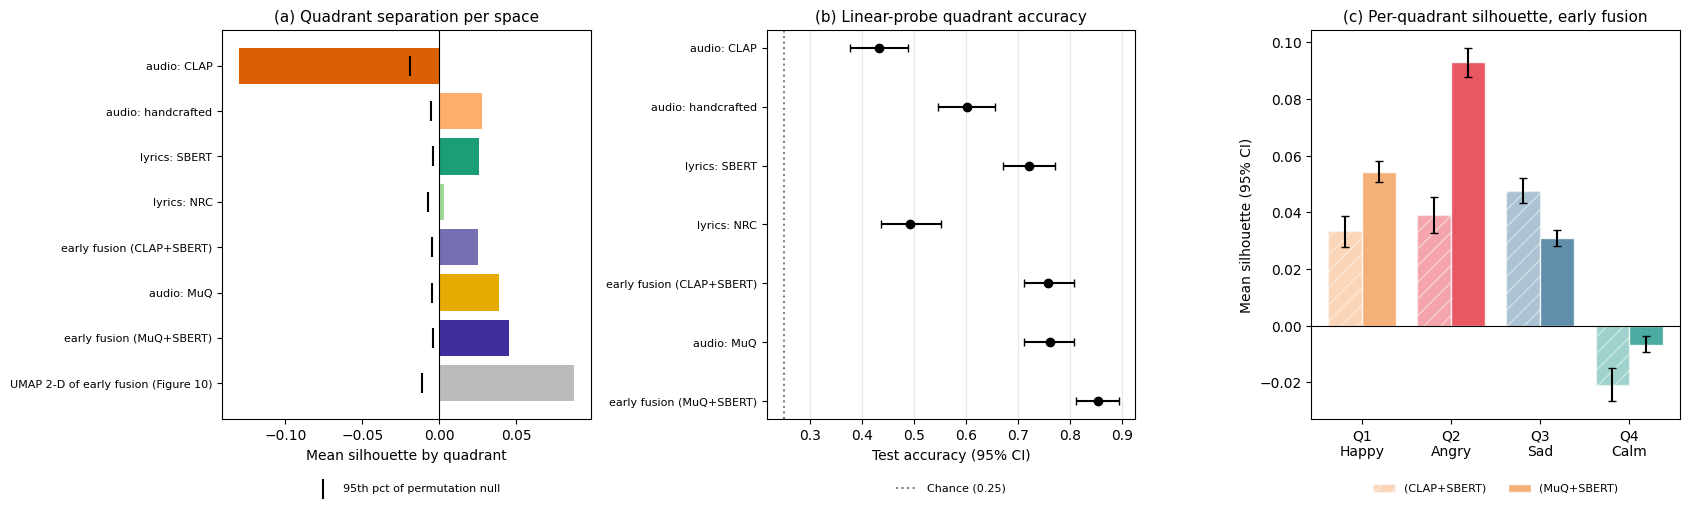

Saved: embedding_structure.png, embedding_silhouette.csv, linear_probe_quadrant.csv, coherence_vs_boundary.csv


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
ax = axes[0]
order = list(SPACES) + ['UMAP 2-D of early fusion (Figure 10)']
BAR_COL = {'audio: CLAP': '#d95f02', 'audio: handcrafted': '#fdae6b', 'lyrics: SBERT': '#1b9e77',
           'lyrics: NRC': '#a1d99b', 'early fusion (CLAP+SBERT)': '#7570b3', 'audio: MuQ': '#e6ab02',
           'early fusion (MuQ+SBERT)': '#3f2f9e', 'UMAP 2-D of early fusion (Figure 10)': '#bbbbbb'}
s = sil.set_index('space').loc[order]
y = np.arange(len(order))[::-1]
ax.barh(y, s.silhouette, color=[BAR_COL[k] for k in order])
ax.scatter(s.null_95th, y, marker='|', s=200, color='black', label='95th pct of permutation null')
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(order, fontsize=8)
ax.set_xlabel('Mean silhouette by quadrant'); ax.set_title('(a) Quadrant separation per space', fontsize=11)
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.14), frameon=False)

ax = axes[1]
p = probe.set_index('features').loc[list(SPACES)]
y = np.arange(len(p))[::-1]
ax.errorbar(p.test_acc, y, xerr=[p.test_acc - p.acc_ci_lo, p.acc_ci_hi - p.test_acc], fmt='o', color='black', capsize=3)
ax.axvline(0.25, color='gray', ls=':', label='Chance (0.25)')
ax.set_yticks(y); ax.set_yticklabels(p.index, fontsize=8)
ax.set_xlabel('Test accuracy (95% CI)'); ax.set_title('(b) Linear-probe quadrant accuracy', fontsize=11)
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.14), frameon=False); ax.grid(axis='x', alpha=0.3)

ax = axes[2]
x = np.arange(4); w = 0.38
for k, (space, hatch) in enumerate([('early fusion (CLAP+SBERT)', '//'), ('early fusion (MuQ+SBERT)', None)]):
    g = qsil[qsil.space == space]
    ax.bar(x + (k - 0.5) * w, g.mean_silhouette, w, color=[QCOL[q] for q in QUADS], alpha=0.85 if hatch is None else 0.45,
           hatch=hatch, edgecolor='white', yerr=[g.mean_silhouette - g.ci_lo, g.ci_hi - g.mean_silhouette], capsize=3,
           label=space.replace('early fusion ', ''))
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([f'{q}\n{QLAB[q]}' for q in QUADS])
ax.set_ylabel('Mean silhouette (95% CI)'); ax.set_title('(c) Per-quadrant silhouette, early fusion', fontsize=11)
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.14), frameon=False, ncol=2)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'embedding_structure.png'), dpi=200, bbox_inches='tight')
plt.show()
print('Saved: embedding_structure.png, embedding_silhouette.csv, linear_probe_quadrant.csv, coherence_vs_boundary.csv')